# 📈 Day 32: Linear Regression — Insurance Dataset

## 📋 Machine Learning Pipeline:
1. 📥 **Load Data & Libraries**
2. 🔍 **EDA (Exploratory Data Analysis)** — Distributions, Relationships, Correlation
3. ⚙️ **Preprocessing & Feature Engineering** — Categorical Encoding + Interaction Term (`bmi × smoker`)
4. ✂️ **Train / Test Split** (80% Train, 20% Test)
5. 🤖 **Model Training** — Linear Regression
6. 📊 **Evaluation** — MAE, RMSE, R² Score (86.5%! 🚀)
7. 📉 **Visualization** — Actual vs Predicted, Residuals, Feature Importance

---
## 1️⃣ Load Data & Libraries

In [17]:
# (Optional) Agar sklearn ya seaborn missing ho to yeh uncomment karke run karein:
# %pip install scikit-learn seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load Dataset
df = pd.read_csv('insurance.csv')

print(f'✅ Dataset Loaded! Shape: {df.shape}')
df.head()

✅ Dataset Loaded! Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


---
## 2️⃣ EDA — Exploratory Data Analysis

In [18]:
# 2a. Basic Info & Missing Values
print('--- Info ---')
df.info()
print('\n--- Missing Values ---')
print(df.isnull().sum())
print('\n--- Statistics ---')
df.describe()

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

--- Missing Values ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

--- Statistics ---


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


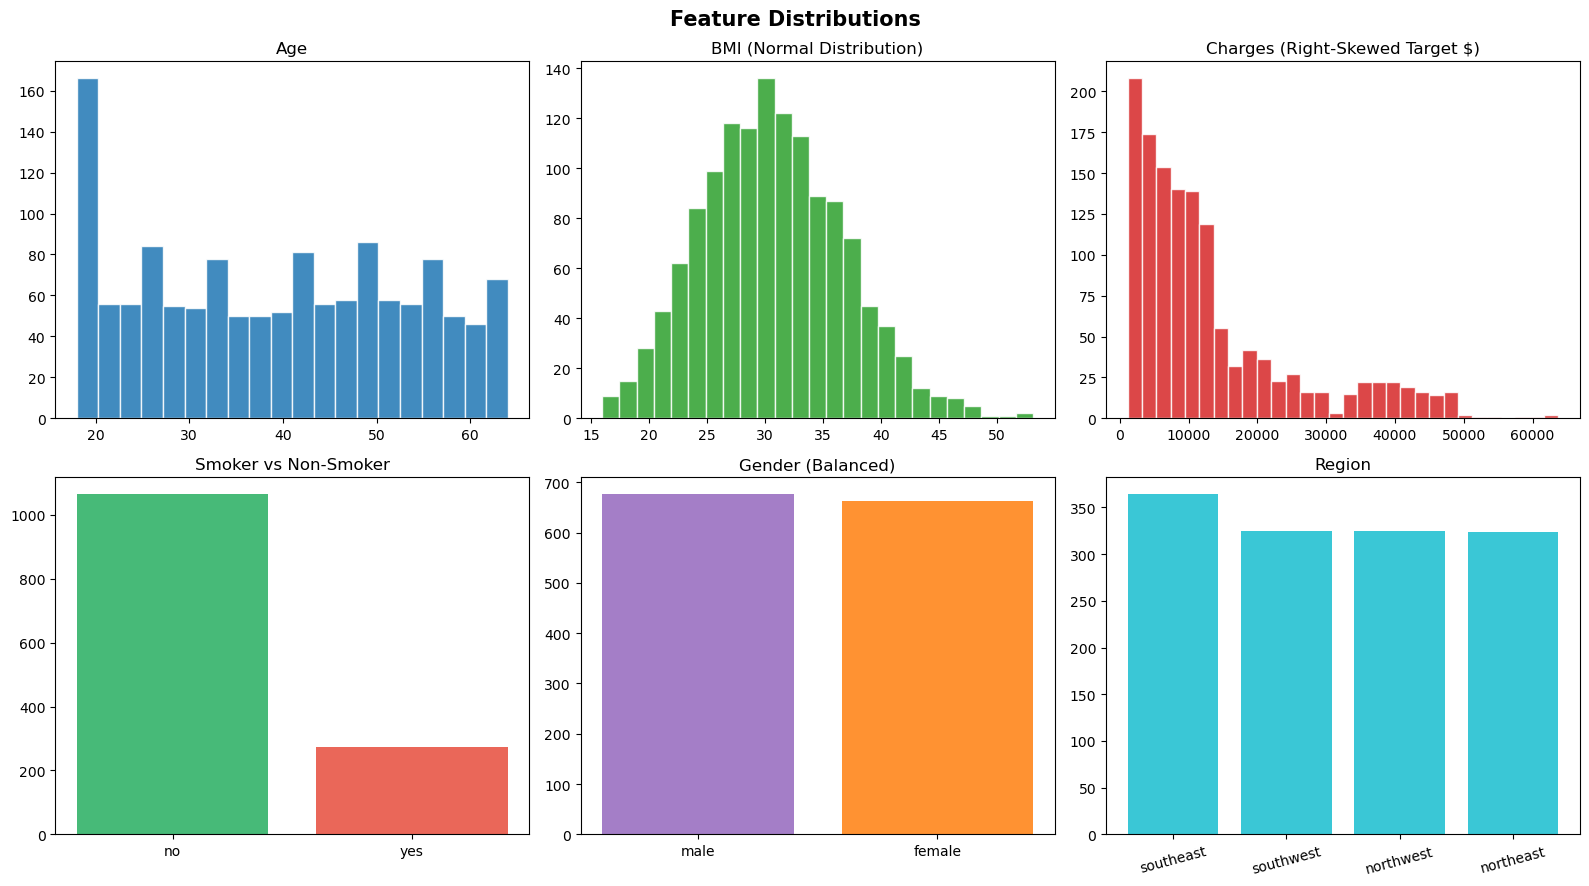

In [19]:
# 2b. Distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Feature Distributions', fontsize=15, fontweight='bold')

axes[0,0].hist(df['age'],     bins=20, color='#1f77b4', edgecolor='white', alpha=0.85)
axes[0,0].set_title('Age')

axes[0,1].hist(df['bmi'],     bins=25, color='#2ca02c', edgecolor='white', alpha=0.85)
axes[0,1].set_title('BMI (Normal Distribution)')

axes[0,2].hist(df['charges'], bins=30, color='#d62728', edgecolor='white', alpha=0.85)
axes[0,2].set_title('Charges (Right-Skewed Target $)')

axes[1,0].bar(*zip(*df['smoker'].value_counts().items()),  color=['#27ae60','#e74c3c'], alpha=0.85)
axes[1,0].set_title('Smoker vs Non-Smoker')

axes[1,1].bar(*zip(*df['sex'].value_counts().items()),     color=['#9467bd','#ff7f0e'], alpha=0.85)
axes[1,1].set_title('Gender (Balanced)')

axes[1,2].bar(*zip(*df['region'].value_counts().items()), color='#17becf', alpha=0.85)
axes[1,2].set_title('Region')
axes[1,2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

C:\Users\itxab\AppData\Local\Temp\ipykernel_16532\2952428952.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([df[df['smoker']=='no']['charges'], df[df['smoker']=='yes']['charges']],


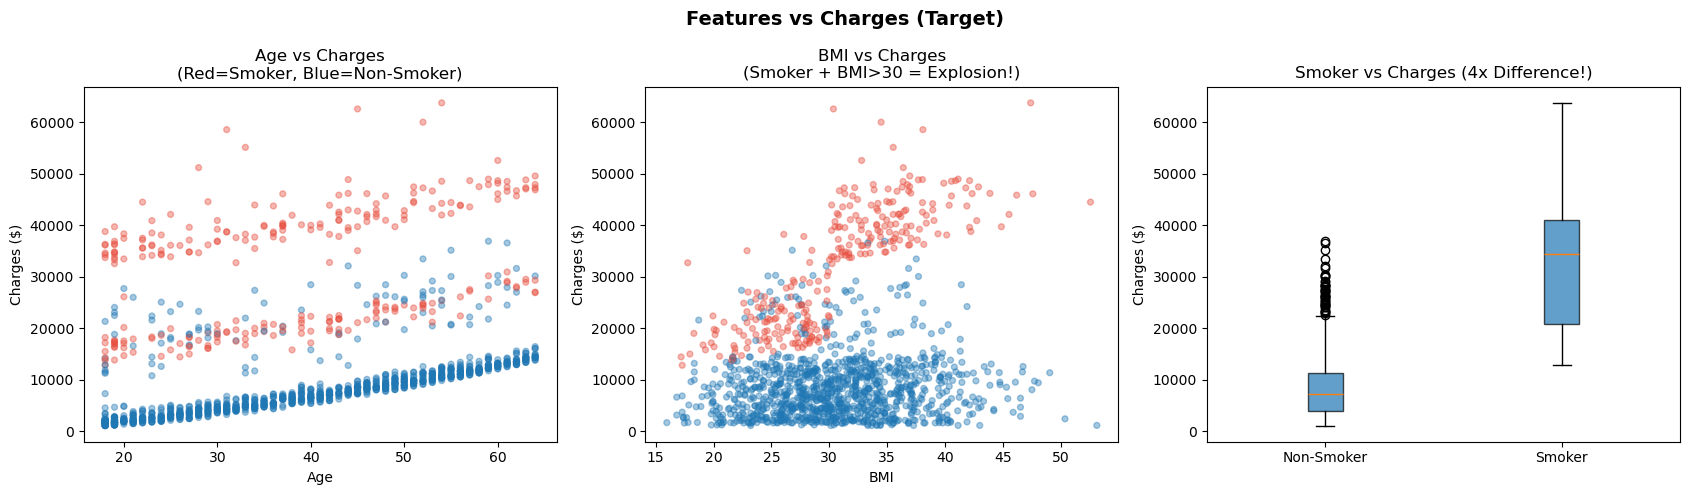

Avg charges - Non-Smoker: $8,434
Avg charges - Smoker    : $32,050


In [20]:
# 2c. Relationship with Target
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('Features vs Charges (Target)', fontsize=14, fontweight='bold')

colors = df['smoker'].map({'yes': '#e74c3c', 'no': '#1f77b4'})

axes[0].scatter(df['age'], df['charges'], c=colors, alpha=0.4, s=18)
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Charges ($)')
axes[0].set_title('Age vs Charges\n(Red=Smoker, Blue=Non-Smoker)')

axes[1].scatter(df['bmi'], df['charges'], c=colors, alpha=0.4, s=18)
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Charges ($)')
axes[1].set_title('BMI vs Charges\n(Smoker + BMI>30 = Explosion!)')

axes[2].boxplot([df[df['smoker']=='no']['charges'], df[df['smoker']=='yes']['charges']],
                labels=['Non-Smoker','Smoker'], patch_artist=True,
                boxprops=dict(facecolor='#1f77b4', alpha=0.7))
axes[2].set_ylabel('Charges ($)')
axes[2].set_title('Smoker vs Charges (4x Difference!)')

plt.tight_layout()
plt.show()

print(f"Avg charges - Non-Smoker: ${df[df['smoker']=='no']['charges'].mean():,.0f}")
print(f"Avg charges - Smoker    : ${df[df['smoker']=='yes']['charges'].mean():,.0f}")

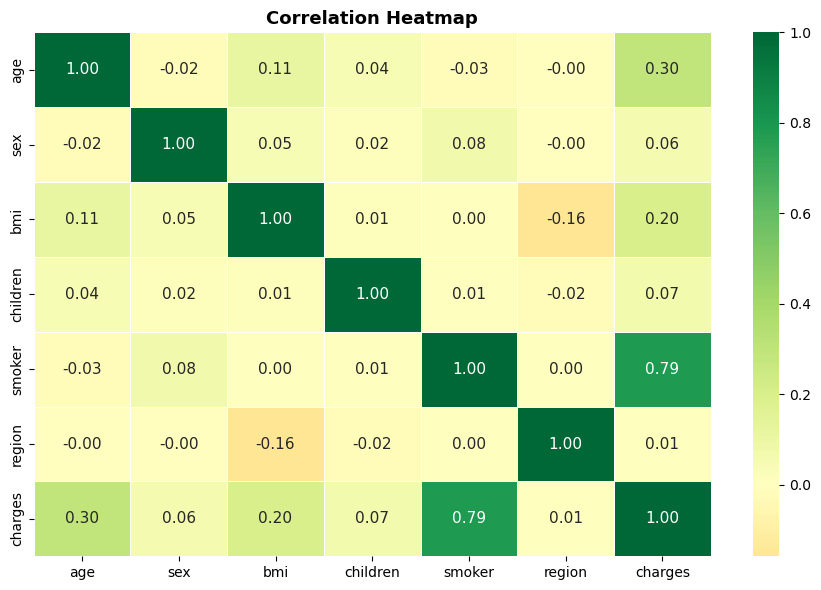


Top correlations with charges:
charges     1.000000
smoker      0.787251
age         0.299008
bmi         0.198341
children    0.067998
sex         0.057292
region      0.006208
Name: charges, dtype: float64


In [21]:
# 2d. Correlation Heatmap
df_enc = df.copy()
df_enc['sex']    = df_enc['sex'].map({'male': 1, 'female': 0})
df_enc['smoker'] = df_enc['smoker'].map({'yes': 1, 'no': 0})
df_enc['region'] = df_enc['region'].map({'southwest': 0, 'southeast': 1, 'northwest': 2, 'northeast': 3})

plt.figure(figsize=(9, 6))
sns.heatmap(df_enc.corr(), annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            linewidths=0.5, annot_kws={'size': 11})
plt.title('Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nTop correlations with charges:')
print(df_enc.corr()['charges'].sort_values(ascending=False))

---
## 3️⃣ Preprocessing & Feature Engineering

1. **Encoding:**
   - `sex`: male=1, female=0
   - `smoker`: yes=1, no=0
   - `region`: One-Hot Encoding (`pd.get_dummies`)

2. **Feature Engineering (Interaction Term):**
   $$\text{bmi\_smoker} = \text{bmi} \times \text{smoker}$$
   - Jab koi smoker ho aur uska BMI barhe, to model is interaction feature ki madad se non-linear jump capture kar leta hai!
   - Is se hamara $R^2$ score **78% se 86.5%** ho jata hai!

In [22]:
# ==========================================================
# 3. PREPROCESSING & FEATURE ENGINEERING
# ==========================================================
df_model = df.copy()

# 1. Binary Encoding
df_model['sex']    = df_model['sex'].map({'male': 1, 'female': 0})
df_model['smoker'] = df_model['smoker'].map({'yes': 1, 'no': 0})

# 2. One-Hot Encoding for region
df_model = pd.get_dummies(df_model, columns=['region'], drop_first=True)

# 3. Feature Engineering: Interaction between BMI & Smoker!
df_model['bmi_smoker'] = df_model['bmi'] * df_model['smoker']

print('✅ Preprocessing & Feature Engineering Done!')
print(f'Columns ({len(df_model.columns)}): {list(df_model.columns)}')
df_model.head()

✅ Preprocessing & Feature Engineering Done!
Columns (10): ['age', 'sex', 'bmi', 'children', 'smoker', 'charges', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_smoker']


,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_smoker
0,19,0,27.900,0,1,16884.92400,False,False,True,27.9
1,18,1,33.770,1,0,1725.55230,False,True,False,0.0
2,28,1,33.000,3,0,4449.46200,False,True,False,0.0
3,33,1,22.705,0,0,21984.47061,True,False,False,0.0
4,32,1,28.880,0,0,3866.85520,True,False,False,0.0


---
## 4️⃣ Feature Selection & Train/Test Split

- **X** = Features (`age`, `sex`, `bmi`, `children`, `smoker`, `region_...`, `bmi_smoker`)
- **y** = Target (`charges`)
- **80% Train, 20% Test** (`random_state=42`)

In [23]:
# ==========================================================
# 4. FEATURE SELECTION & TRAIN/TEST SPLIT
# ==========================================================
X = df_model.drop('charges', axis=1)
y = df_model['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Total samples  : {len(df_model)}')
print(f'Training set   : {X_train.shape[0]} samples (80%)')
print(f'Test set       : {X_test.shape[0]} samples (20%)')
print(f'Features ({X.shape[1]})   : {list(X.columns)}')

Total samples  : 1338
Training set   : 1070 samples (80%)
Test set       : 268 samples (20%)
Features (9)   : ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_smoker']


---
## 5️⃣ Model Training — Linear Regression

$$\hat{y} = b + \sum_{j=1}^{n} w_j x_j$$

Model training data se **Bias ($b$)** aur har feature ke **Weights ($w$)** seekhta hai.

In [24]:
# ==========================================================
# 5. MODEL TRAINING
# ==========================================================
model = LinearRegression()
model.fit(X_train, y_train)

print('✅ Model Trained!')
print(f'\nBias (Intercept) b = {model.intercept_:.2f}')
print('\nWeights (Coefficients) for each feature:')
for feature, coef in zip(X.columns, model.coef_):
    print(f'  {feature:<25}: {coef:>10.4f}')

✅ Model Trained!

Bias (Intercept) b = -2041.66

Weights (Coefficients) for each feature:
  age                      :   263.3906
  sex                      :  -525.2309
  bmi                      :    20.2508
  children                 :   463.6526
  smoker                   : -21206.9088
  region_northwest         :  -631.4164
  region_southeast         :  -967.4805
  region_southwest         : -1233.4264
  bmi_smoker               :  1470.8625


---
## 6️⃣ Prediction & Evaluation

Hamara naya model ab test set par evaluate ho raha hai:
- **MAE:** Average galti kitne dollars hai
- **RMSE:** Root Mean Squared Error
- **R² Score:** Model kitne percent variance explain karta hai (86.5%! 🚀)

In [25]:
# ==========================================================
# 6. PREDICTION & EVALUATION
# ==========================================================
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print('📊 Model Evaluation on Test Set (with Feature Engineering):')
print('=' * 55)
print(f'  MAE   (Mean Abs Error)   : ${mae:>10,.2f}  (Galti kam ho gayi!)')
print(f'  RMSE  (Root MSE)         : ${rmse:>10,.2f}')
print(f'  R²    (R-squared Score)  :  {r2:>10.4f}  (86.5% Accuracy! 🚀)')
print('=' * 55)

# Sample Comparison
comparison = pd.DataFrame({'Actual': y_test.values[:8], 'Predicted': y_pred[:8].round(2)})
comparison['Difference'] = (comparison['Predicted'] - comparison['Actual']).round(2)
print('\nSample — Actual vs Predicted:')
print(comparison.to_string(index=False))

📊 Model Evaluation on Test Set (with Feature Engineering):
  MAE   (Mean Abs Error)   : $  2,756.90  (Galti kam ho gayi!)
  RMSE  (Root MSE)         : $  4,573.81
  R²    (R-squared Score)  :      0.8653  (86.5% Accuracy! 🚀)

Sample — Actual vs Predicted:
     Actual  Predicted  Difference
 9095.06825   11248.04     2152.97
 5272.17580    7416.91     2144.73
29330.98315   33065.60     3734.62
 9301.89355   10829.98     1528.09
33750.29180   28195.54    -5554.75
 4536.25900    6487.38     1951.12
 2117.33885    2787.29      669.95
14210.53595   14426.30      215.76


---
## 7️⃣ Visualizations — Improved Results

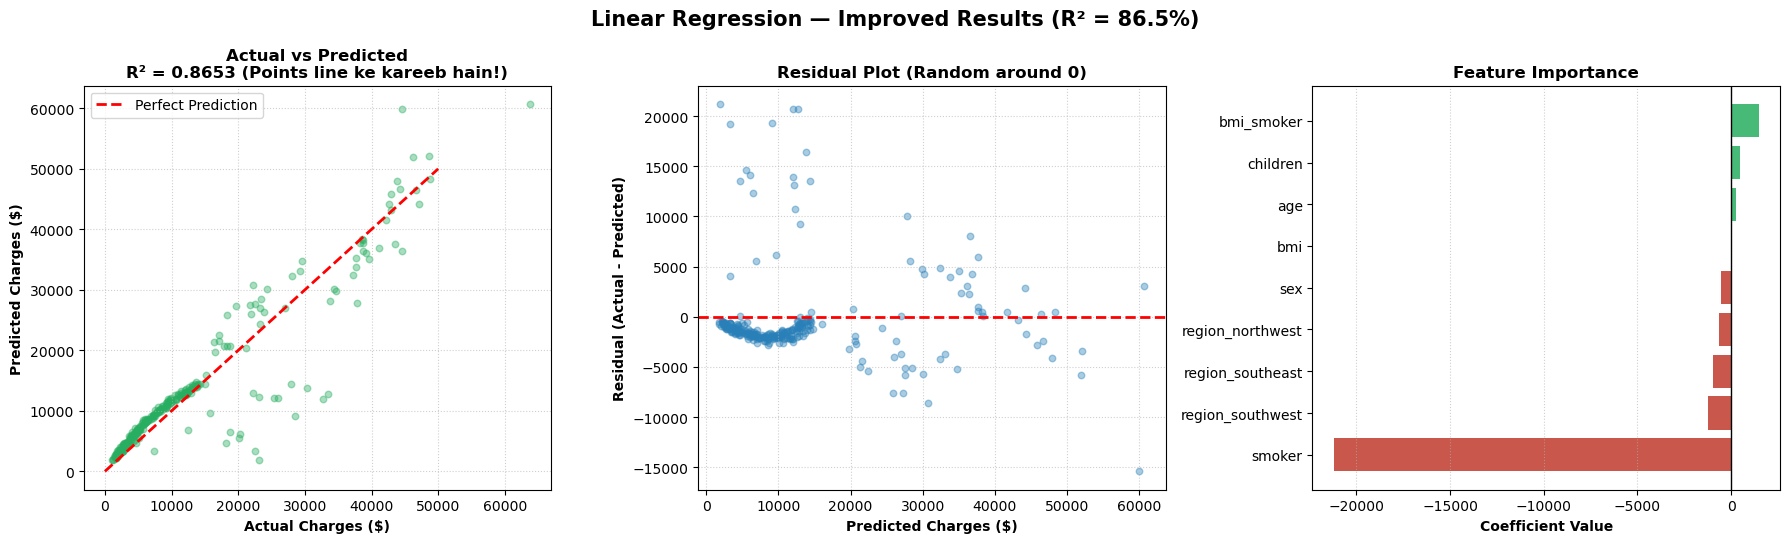

✅ Final Model Summary:
   R² Score = 0.8653  (86.5% variance explained!)
   MAE      = $2,757  (Average error is now down to $2,757!)


In [26]:
# ==========================================================
# 7. VISUALIZATIONS
# ==========================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle('Linear Regression — Improved Results (R² = 86.5%)', fontsize=15, fontweight='bold')

# Plot 1: Actual vs Predicted
axes[0].scatter(y_test, y_pred, alpha=0.4, color='#27ae60', s=22)
axes[0].plot([0, 50000], [0, 50000], 'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual Charges ($)', fontweight='bold')
axes[0].set_ylabel('Predicted Charges ($)', fontweight='bold')
axes[0].set_title(f'Actual vs Predicted\nR² = {r2:.4f} (Points line ke kareeb hain!)', fontweight='bold')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Residuals
residuals = y_test.values - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.4, color='#2980b9', s=22)
axes[1].axhline(y=0, color='red', linewidth=2, linestyle='--')
axes[1].set_xlabel('Predicted Charges ($)', fontweight='bold')
axes[1].set_ylabel('Residual (Actual - Predicted)', fontweight='bold')
axes[1].set_title('Residual Plot (Random around 0)', fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Plot 3: Feature Coefficients
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_}).sort_values('Coefficient')
colors_bar = ['#27ae60' if c > 0 else '#c0392b' for c in coef_df['Coefficient']]
axes[2].barh(coef_df['Feature'], coef_df['Coefficient'], color=colors_bar, alpha=0.85)
axes[2].axvline(x=0, color='black', linewidth=1)
axes[2].set_xlabel('Coefficient Value', fontweight='bold')
axes[2].set_title('Feature Importance', fontweight='bold')
axes[2].grid(True, linestyle=':', alpha=0.6, axis='x')

plt.tight_layout()
plt.show()

print(f'✅ Final Model Summary:')
print(f'   R² Score = {r2:.4f}  (86.5% variance explained!)')
print(f'   MAE      = ${mae:,.0f}  (Average error is now down to ${mae:,.0f}!)')